Decomposition of LWA Carrying Capacity into different contributions

This notebook follows the analysis by Barpanda et al. 2024 https://doi.org/10.1175/JCLI-D-24-0232.1 and adds several modifications

We want to compute the Total LWA Carrying Capacity:
\begin{equation}
F_c(x) = \frac{C^2(x)}{4\alpha} = \frac{\left( u_0 + \beta + c_g^x - 2\alpha \mathcal{A}_0 \right)^2}{4\alpha}
\end{equation}
In order to do so we need to compute:

- $c_g^x$: this is computed as a regression coefficient between vertically-averaged zonal Eliassen Palm Flux $(𝐹_3)$ and the wave-activity $(A cos\phi)$
- $u_0$: this is computed as the time-averaged reference zonal wind (different from Barpanda and Nakamura, that estimate it through a regression)
- $\alpha$: this is the correlation coefficient between eddy zonal winds and LWA. It can therefore be computed as −($u^′_e$$A^′_𝑇$ )/($A^′$$A^′_𝑇$ )
- $\beta$: this is the intercept of the regression between eddy zonal winds and LWA (not treated in Barpanda and Nakamura but necessary to compare the carrying capacity with the flux)
- ${A}_0$: this is the stationary waves induced local wave activity and can be computed by computing the local wave activity of the time-averaged qgpv field.


In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.util as cutil
import numpy as np
from tqdm import tqdm
import matplotlib.gridspec as gridspec  # To control widths
from scipy.integrate import trapezoid
import falwa.utilities as utilities
from falwa.oopinterface import QGFieldNH18
from math import pi
import cftime

### Necessary functions

In [2]:
def flip_and_append(ds):
    # Step 2: Select Southern Hemisphere data
    ds_sh = ds.sel(lat=slice(-90,0))
    
    # Step 3: Flip the latitude values to Northern Hemisphere
    # Here, we need to change the latitude to positive values (0 to 90)
    ds_sh = ds_sh.assign_coords(lat = abs(ds_sh.lat))
    ds_sh = ds_sh.reindex(lat=list(reversed(ds_sh.lat)))
    
    date_list = []
    for date in ds_sh.time.values:
      date_list.append(cftime.Datetime360Day(date.year + ds_sh.time.values[-1].year, date.month, date.day))
    date_list = np.array(date_list)
    ds_sh = ds_sh.assign_coords(time = date_list)
    
    # Step 4: Concatenate the original dataset with the flipped Southern Hemisphere data
    # Assuming 'time' is the coordinate you want to concatenate along
    combined_ds = xr.concat([ds, ds_sh], dim='time')
    latitude = ds_sh['lat']
    ds_positive_latitudes = combined_ds.sel(lat=latitude[latitude >= 0])
    return ds_positive_latitudes

In [3]:
from scipy.signal import butter, filtfilt

import xarray as xr
import numpy as np

import xarray as xr

import xarray as xr

def rolling_periodic(
    da: xr.DataArray,
    dim: str,
    window: int,
    center: bool = True
) -> xr.DataArray:

    n = window // 2 if center else window - 1

    # Extend array by wrapping values from both ends along chosen dimension
    da_extended = xr.concat([da.isel({dim: slice(-n, None)}),
                             da,
                             da.isel({dim: slice(0, n)})],
                            dim=dim)

    # Apply rolling mean
    rolled = da_extended.rolling({dim: window}, center=center).mean()

    # Trim back to original length
    result = rolled.isel({dim: slice(n, -n)})
    result[dim] = da[dim]  # restore original coords

    return result

def lowpass_fourier(da, period_days=4 , dt=1, time_dim='time'):
    
    n_time = da.sizes[time_dim]

    # FFT frequencies (cycles per day)
    freqs = np.fft.fftfreq(n_time, d=dt)
    cutoff = 1 / period_days  # max frequency to keep

    # FFT along time axis
    fft_vals = np.fft.fft(da, axis=0)

    # Low-pass mask
    mask = np.abs(freqs) <= cutoff
    fft_vals_filtered = fft_vals * mask[:, np.newaxis, np.newaxis]

    # Inverse FFT
    filtered_data = np.fft.ifft(fft_vals_filtered, axis=0).real

    return xr.DataArray(filtered_data, dims=da.dims, coords=da.coords, name=da.name)

def longitude_running_avg(da, lon_window_deg=15, lon_dim='lon'):
    # Compute number of points corresponding to lon_window_deg
    lon_vals = da[lon_dim].values
    if len(lon_vals) > 1:
        lon_res = np.mean(np.diff(lon_vals))
        window_points = max(1, int(np.round(lon_window_deg / lon_res)))
    else:
        window_points = 1

    print('longitudinal filter window: '+ str(window_points))

    # Apply rolling mean along longitude
    da_smoothed = rolling_periodic(da, lon_dim , window = window_points, center=True)
    return da_smoothed

def deseasonalize_daily(da):
    daily_clim = da.groupby("time.dayofyear").mean("time")
    anomalies = da.groupby("time.dayofyear") - daily_clim    
    return anomalies

def deseasonalize_roll(da):
    running_mean = rolling_periodic(da=da,dim='time',window=30,center=True)
    anomalies = da - running_mean  
    return anomalies

In [4]:
import numpy as np
import xarray as xr
from tqdm import tqdm

def _prep(A, B):
    """Convert once to numpy with time as axis 0; return arrays, output template, NaN flag."""
    A = A.transpose('time', ...)
    B = B.transpose('time', ...)
    template = A.isel(time=0, drop=True)
    a, b = A.values, B.values            # loads dask arrays once
    has_nan = bool(np.isnan(a).any() or np.isnan(b).any())
    return a, b, template, has_nan

def compute_covariance_xr(A: xr.DataArray, B: xr.DataArray) -> xr.DataArray:
    a, b, template, has_nan = _prep(A, B)
    mean = np.nanmean if has_nan else np.mean
    cov = mean((a - mean(a, axis=0)) * (b - mean(b, axis=0)), axis=0)
    return template.copy(data=cov).rename('cov')

def covariance_bootstrap(A, B, n_iterations=50, n_sample=1000, seed=None):
    rng = np.random.default_rng(seed)
    a, b, template, has_nan = _prep(A, B)
    length = a.shape[0]
    mean = np.nanmean if has_nan else np.mean

    covs = np.empty((n_iterations,) + a.shape[1:], dtype=np.float64)
    for n in tqdm(range(n_iterations)):
        idxs = np.sort(rng.choice(length, size=n_sample, replace=False))  # sorted: better memory access
        covs[n] = mean((As - mean(As, axis=0)) * (Bs - mean(Bs, axis=0)), axis=0)

    std = covs.std(axis=0) * (np.sqrt(n_sample) / np.sqrt(length))
    return template.copy(data=std)

#this bootstrap takes into account the fact that the time series is not composed of independent values
#when bootstrapping the temporal autocorrelation is preserved by analyzing 40 series of 100 blocks
def slope_block_bootstrap(A, B, n_iterations=50, n_blocks=40, block_len=100, seed=None):
    rng = np.random.default_rng(seed)
    a, b, template, has_nan = _prep(A, B)
    length = a.shape[0]
    mean = np.nanmean if has_nan else np.mean

    slopes = np.empty((n_iterations,) + a.shape[1:], dtype=np.float64)
    for n in tqdm(range(n_iterations)):
        starts = rng.integers(0, length - block_len + 1, size=n_blocks)
        idxs = (starts[:, None] + np.arange(block_len)).ravel()    # vectorised, no Python list

        As, Bs = a[idxs], b[idxs]
        Aa = As - mean(As, axis=0)                                 # anomalies computed once
        Ba = Bs - mean(Bs, axis=0)
        slopes[n] = mean(Aa * Ba, axis=0) / mean(Aa * Aa, axis=0)  # cov(A,B) / var(A)

    frac = (n_blocks * block_len) / length
    std = slopes.std(axis=0) * np.sqrt(frac)
    return template.copy(data=std)

### Importing data

In [5]:
#here we focus on the asymmetric baseline simulation
%cd /emmy-noether/home/mf671/DATA/isca_data/exeter_project_mf_baseline_KS/falwa_output/

/emmy-noether/home/mf671/DATA/isca_data/exeter_project_mf_baseline_KS/falwa_output


In [6]:
#apply filters (if not done previously)
apply = False
if apply:
    months_range = range(13, 613) #select months range
    files_falwa = [f"falwa_output_1.5x1.5_{str(i).zfill(4)}.nc" for i in months_range]
    ds_fluxs = xr.open_mfdataset(files_falwa, combine="by_coords",parallel=True)
    ds_fluxs = flip_and_append(ds_fluxs)
    lwa = ds_fluxs['dw_lwa']
    ucomp = ds_fluxs['u_baro']
    uref = ds_fluxs['dw_uref']
    F1 = ds_fluxs['adv_flux_f1']
    F2 = ds_fluxs['adv_flux_f2']
    F3 = ds_fluxs['adv_flux_f3']
    qgpv = ds_fluxs['dw_qgpv']
    lwa = longitude_running_avg(lowpass_fourier(lwa))
    ucomp = longitude_running_avg(lowpass_fourier(ucomp))
    F1 = longitude_running_avg(lowpass_fourier(F1))
    F2 = longitude_running_avg(lowpass_fourier(F2))
    F3 = longitude_running_avg(lowpass_fourier(F3))
    qgpv = longitude_running_avg(lowpass_fourier(qgpv))
    ds_filtered = lwa.to_dataset()
    ds_filtered['F1'] = F1
    ds_filtered['F2'] = F2
    ds_filtered['F3'] = F3
    ds_filtered['dw_uref'] = ds_fluxs['dw_uref']
    ds_filtered['dw_qgpv'] = qgpv
    ds_filtered['dw_qref'] = ds_fluxs['dw_qref']
    ds_filtered['ucomp'] = ucomp
    ds_filtered.to_netcdf('../tot/filtered_decomposition_data_flipped_2-51.nc')
    ds_filtered.close()

In [7]:
#import dataset with decomposition data (output of previous cell)
ds = xr.open_dataset('../tot/filtered_decomposition_data_flipped_2-51.nc')
lwa = ds['dw_lwa']
ucomp = ds['ucomp']
qgpv = ds['dw_qgpv']
qref = ds['dw_qref']
uref = ds['dw_uref']
EP_zonal_flux = ds['F3'] #eliassen palm zonal flux
tot_zonal_flux = ds['F1'] + ds['F2'] + ds['F3']
lon = ds['lon']
lat = ds['lat']
cosphi = np.cos(np.deg2rad(lat)).broadcast_like(ucomp)

## Computing $\alpha$ and $\beta$

$\alpha$ measures the anticorrelation between $u_e$ and A, where $u_e = u - u_{ref}$

$\beta$ measures the $u_e$ component that is idependent from A and arises from B, surface wave activity (or baroclinic processes)

In formula they are given by:

$ u_e = −\alpha A + \beta, \alpha,\beta > 0$

Or:

𝛼 = −($u^′_e$$A^′_𝑇$ )/($A^′$$A^′_𝑇$ ), where A′, 𝑢′ 𝑒 are row matrices containing the time-filtered transient LWA and zonal wind, respectively.

In [22]:
print('computing ue')
ue = ucomp-uref
print('computing covariances')
cov = compute_covariance_xr(lwa/cosphi,ue) #covariance
var = compute_covariance_xr(lwa/cosphi,lwa/cosphi) #lwa variance
alpha = (-cov/var).persist()

neg_cov = - cov.copy()
var_lwa = var.copy()
var_ue = compute_covariance_xr(ue,ue)

print('performing bootstrap')
alpha_std = slope_block_bootstrap(lwa/cosphi,ue)

importing ue
computing covariances
performing bootstrap


  0%|                                                                                | 0/50 [00:00<?, ?it/s]/tmp/ipykernel_51047/1056787539.py:50: RuntimeWarning: invalid value encountered in divide
  slopes[n] = mean(Aa * Ba, axis=0) / mean(Aa * Aa, axis=0)  # cov(A,B) / var(A)
100%|███████████████████████████████████████████████████████████████████████| 50/50 [00:50<00:00,  1.01s/it]


In [23]:
#creating a mask to isolate grid points for which the correlation between Ue and A is significant
ue_A_rvalue = neg_cov/np.sqrt(var_lwa*var_ue)
r_mask = np.where(ue_A_rvalue<0.4,1,0)

In [24]:
# Compute the beta (beta0) of the linear relationship: ucomp ≈ -alpha * (lwa/cosphi) + beta
lwa_mean = (lwa / cosphi).mean(dim='time')
ue_mean = ue.mean(dim='time')
beta = (ue_mean + alpha * lwa_mean).persist()
beta_std = abs(alpha_std*lwa_mean)

In [25]:
print('computing zonal average')
da_avg = alpha.mean(axis=-1).values
alpha_zon_mean = np.broadcast_to(da_avg[:, np.newaxis], alpha.shape)

computing zonal average


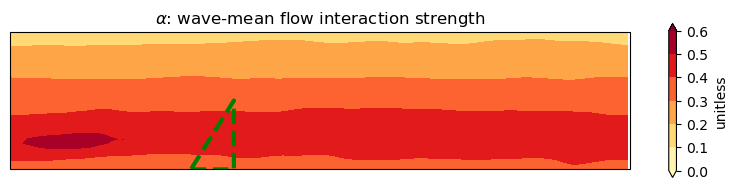

In [26]:
import cartopy.feature as cfeature

fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(10, 4))

# Set extent: lon from -180 to 180, lat from 25 to 75
ax.set_extent([-180, 180, 25, 75], crs=ccrs.PlateCarree())

# Plot the filled contours
contour = ax.contourf(
    lon, lat, alpha,
    levels=np.arange(0, 0.7, 0.1),
    cmap='YlOrRd',
    extend='both',
    transform=ccrs.PlateCarree()
)

#triangle coordinates
coords = [
    (-75.0, 25.0),  # Point A
    (-50.0, 25.0),  # Point B
    (-50.0, 50.0)   # Point C
]
# Unzip into separate lists of longitudes and latitudes, and close the triangle
lons, lats = zip(*coords)
lons += (lons[0],)
lats += (lats[0],)

ax.plot(lons, lats, linestyle='--',linewidth=3, color='green', transform=ccrs.PlateCarree())

ax.set_aspect(1.6)

# Add colorbar
cbar = plt.colorbar(contour, ax=ax, orientation='vertical', label='unitless',shrink=0.5)
plt.title(r'$\alpha$: wave-mean flow interaction strength')

plt.show()


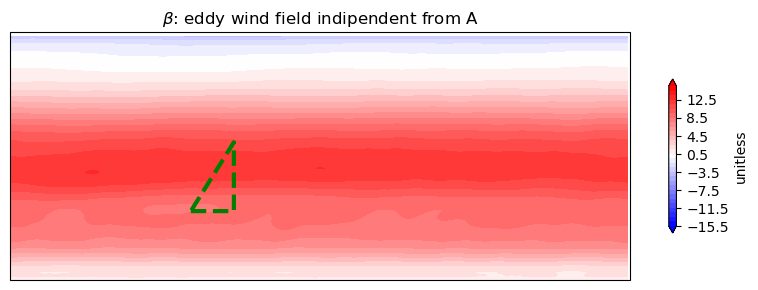

In [27]:
import cartopy.feature as cfeature

fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(10, 4))

# Set extent: lon from -180 to 180, lat from 25 to 75
ax.set_extent([-180, 180, 0, 90], crs=ccrs.PlateCarree())

# Plot the filled contours
contour = ax.contourf(
    lon, lat, beta,
    levels=np.arange(-15.5,16,1),
    cmap='bwr',
    extend='both',
    transform=ccrs.PlateCarree()
)

#triangle coordinates
coords = [
    (-75.0, 25.0),  # Point A
    (-50.0, 25.0),  # Point B
    (-50.0, 50.0)   # Point C
]
# Unzip into separate lists of longitudes and latitudes, and close the triangle
lons, lats = zip(*coords)
lons += (lons[0],)
lats += (lats[0],)

ax.plot(lons, lats, linestyle='--',linewidth=3, color='green', transform=ccrs.PlateCarree())

ax.set_aspect(1.6)

# Add colorbar
cbar = plt.colorbar(contour, ax=ax, orientation='vertical', label='unitless',shrink=0.5)
plt.title(r'$\beta$: eddy wind field indipendent from A')

plt.show()

In [28]:
#Testing the fluxes approximation 

#location_for_test = -10.5,51 #region of maximum covariance
#location_for_test = +20.5,71 #region of minimum covariance
#location_for_test = -70,25 #storm track entrance
#location_for_test = 10,55 #region of European blocking
#location_for_test = -45,70 #region of Greenland blocking
location_for_test = -40,35 #storm track core
#location_for_test = -24,54 #region of maximum covariance

cosphi_1D = np.cos(np.deg2rad(location_for_test[1]))
lwa_1D = lwa.sel(lat=location_for_test[1], lon=location_for_test[0], method='nearest').values
ucomp_1D = ucomp.sel(lat=location_for_test[1], lon=location_for_test[0], method='nearest').values
ue_1D = ue.sel(lat=location_for_test[1], lon=location_for_test[0], method='nearest').values
u0_1D = uref.mean('time').sel(lat=location_for_test[1], method='nearest').values
alpha_1D = alpha.sel(lat=location_for_test[1], lon=location_for_test[0], method='nearest').values
beta_1D = beta.sel(lat=location_for_test[1], lon=location_for_test[0], method='nearest').values

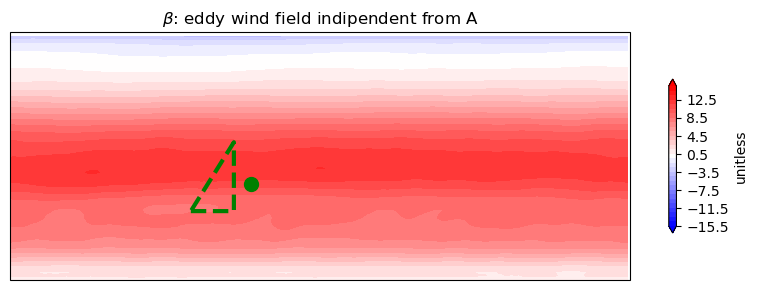

In [29]:
import cartopy.feature as cfeature

fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(10, 4))

# Set extent: lon from -180 to 180, lat from 25 to 75
ax.set_extent([-180, 180, 0, 90], crs=ccrs.PlateCarree())

# Plot the filled contours
contour = ax.contourf(
    lon, lat, beta,
    levels=np.arange(-15.5,16,1),
    cmap='bwr',
    extend='both',
    transform=ccrs.PlateCarree()
)

#triangle coordinates
coords = [
    (-75.0, 25.0),  # Point A
    (-50.0, 25.0),  # Point B
    (-50.0, 50.0)   # Point C
]
# Unzip into separate lists of longitudes and latitudes, and close the triangle
lons, lats = zip(*coords)
lons += (lons[0],)
lats += (lats[0],)

ax.plot(lons, lats, linestyle='--',linewidth=3, color='green', transform=ccrs.PlateCarree())
ax.plot(location_for_test[0], location_for_test[1], marker='o', color='green', markersize=10, transform=ccrs.PlateCarree())

ax.set_aspect(1.6)

# Add colorbar
cbar = plt.colorbar(contour, ax=ax, orientation='vertical', label='unitless',shrink=0.5)
plt.title(r'$\beta$: eddy wind field indipendent from A')

plt.show()

Text(0.5, 0, 'A [m/s]')

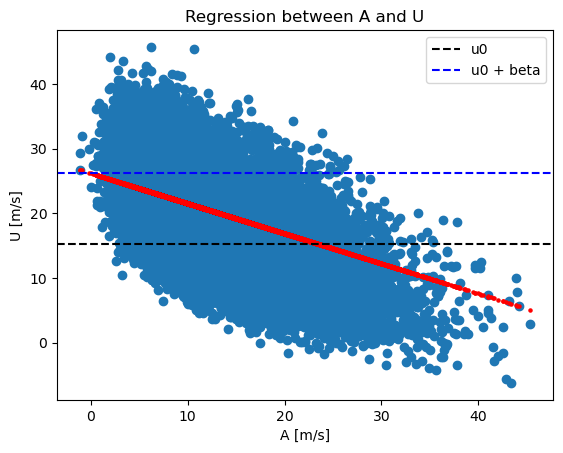

In [30]:
U_approx = (-lwa_1D*alpha_1D + beta_1D + u0_1D)
plt.axhline(u0_1D, color='black', linestyle='--', label='u0')
plt.axhline(u0_1D+beta_1D, color='blue', linestyle='--', label='u0 + beta')
plt.scatter(lwa_1D,ucomp_1D)
plt.scatter(lwa_1D,U_approx,color='Red',s=5)
plt.title('Regression between A and U')
plt.legend()
plt.ylabel('U [m/s]')
plt.xlabel('A [m/s]')

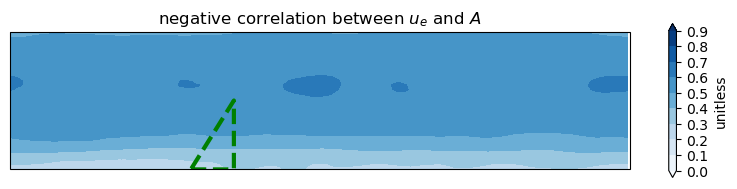

In [32]:
import cartopy.feature as cfeature

fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(10, 4))

# Set extent: lon from -180 to 180, lat from 25 to 75
ax.set_extent([-180, 180, 25, 75], crs=ccrs.PlateCarree())

# Plot the filled contours
contour = ax.contourf(
    lon, lat, neg_cov/np.sqrt(var_lwa*var_ue),
    levels=np.arange(0, 1, 0.1),
    cmap='Blues',
    extend='both',
    transform=ccrs.PlateCarree()
)

#triangle coordinates
coords = [
    (-75.0, 25.0),  # Point A
    (-50.0, 25.0),  # Point B
    (-50.0, 50.0)   # Point C
]
# Unzip into separate lists of longitudes and latitudes, and close the triangle
lons, lats = zip(*coords)
lons += (lons[0],)
lats += (lats[0],)

ax.plot(lons, lats, linestyle='--',linewidth=3, color='green', transform=ccrs.PlateCarree())

ax.set_aspect(1.6)

# Add colorbar
cbar = plt.colorbar(contour, ax=ax, orientation='vertical', label='unitless',shrink=0.5)
plt.title(r'negative correlation between $u_e$ and $A$')

plt.show()

## Computing $c_g$

$c_g^x$ (or zgv) is computed as a regression coefficient between vertically-averaged linear zonal LWA flux from radiation stress $𝐹_3$ and the wave-activity $(A cos\phi)$

In [33]:
print('computing covariances')
cov = compute_covariance_xr(lwa,EP_zonal_flux)
var = compute_covariance_xr(lwa,lwa)
zgv = (cov/var).persist()

#compute error
zgv_std = slope_block_bootstrap(lwa,EP_zonal_flux)

computing covariances


/tmp/ipykernel_51047/1056787539.py:17: RuntimeWarning: Mean of empty slice
  cov = mean((a - mean(a, axis=0)) * (b - mean(b, axis=0)), axis=0)
  0%|                                                                                | 0/50 [00:00<?, ?it/s]/tmp/ipykernel_51047/1056787539.py:49: RuntimeWarning: Mean of empty slice
  Ba = Bs - mean(Bs, axis=0)
/tmp/ipykernel_51047/1056787539.py:50: RuntimeWarning: Mean of empty slice
  slopes[n] = mean(Aa * Ba, axis=0) / mean(Aa * Aa, axis=0)  # cov(A,B) / var(A)
100%|███████████████████████████████████████████████████████████████████████| 50/50 [01:41<00:00,  2.02s/it]


In [34]:
print('performing zonal average')
da_avg = zgv.mean(axis=-1).values
GV_zon_mean = np.broadcast_to(da_avg[:, np.newaxis], zgv.shape)

performing zonal average


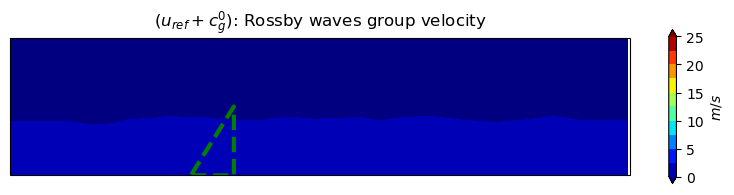

In [35]:
import cartopy.feature as cfeature

fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(10, 4))

# Set extent: lon from -180 to 180, lat from 25 to 75
ax.set_extent([-180, 180, 25, 75], crs=ccrs.PlateCarree())

# Plot the filled contours
contour = ax.contourf(
    lon,lat,zgv,
    levels=np.arange(0, 26, 2.5),
    cmap='jet',#'YlOrRd',
    extend='both',
    transform=ccrs.PlateCarree()
)

ax.plot(lons, lats, linestyle='--',linewidth=3, color='green', transform=ccrs.PlateCarree())

# Add coastlines and optional borders
ax.set_aspect(1.6)
#ax.coastlines(color='black', linewidth=0.8)
#ax.add_feature(cfeature.BORDERS, linewidth=0.5)

# Add colorbar
cbar = plt.colorbar(contour, ax=ax, orientation='vertical', label='$m/s$',shrink=0.5)
plt.title('$(u_{ref} + c^0_g)$: Rossby waves group velocity')

plt.show()

## Computing $u_0$

$u_0$ is simply the temporal average of the reference zonal wind.

In [36]:
u_0 = uref.mean('time').broadcast_like(zgv)

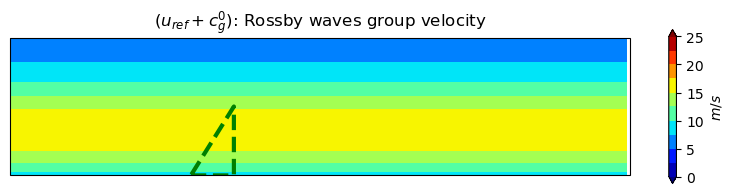

In [37]:
import cartopy.feature as cfeature

fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(10, 4))

# Set extent: lon from -180 to 180, lat from 25 to 75
ax.set_extent([-180, 180, 25, 75], crs=ccrs.PlateCarree())

# Plot the filled contours
contour = ax.contourf(
    lon,lat,u_0,
    levels=np.arange(0, 26, 2.5),
    cmap='jet',#'YlOrRd',
    extend='both',
    transform=ccrs.PlateCarree()
)

ax.plot(lons, lats, linestyle='--',linewidth=3, color='green', transform=ccrs.PlateCarree())

# Add coastlines and optional borders
ax.set_aspect(1.6)
#ax.coastlines(color='black', linewidth=0.8)
#ax.add_feature(cfeature.BORDERS, linewidth=0.5)

# Add colorbar
cbar = plt.colorbar(contour, ax=ax, orientation='vertical', label='$m/s$',shrink=0.5)
plt.title('$(u_{ref} + c^0_g)$: Rossby waves group velocity')

plt.show()

## Computing $A_0$

The stationary local wave activity is obtained by computing the local wave activity associated to monthly averaged qgpv field and then averaging the so-obtained values. (it is done in a separate notebook)

In [38]:
ds_sl = xr.open_dataset('../tot/dw_stat_lwa_2-51.nc').where(ds.lat >= 0, drop=True)
print(ds)
print('data imported')
slwa = xr.zeros_like(ds_sl['dw_stat_lwa']) #symmetric case correction
slwa_std = xr.zeros_like(ds_sl['dw_stat_lwa_std']) #symmetric case correction

#the relative error is much smaller than for the other quantities so we do not include it in the analysis for simplicity

<xarray.Dataset> Size: 25GB
Dimensions:  (lat: 61, time: 36000, lon: 240)
Coordinates:
  * lat      (lat) float64 488B 0.0 1.5 3.0 4.5 6.0 ... 84.0 85.5 87.0 88.5 90.0
  * time     (time) object 288kB 0002-01-02 00:00:00 ... 0104-01-01 00:00:00
  * lon      (lon) float64 2kB -180.0 -178.5 -177.0 -175.5 ... 175.5 177.0 178.5
Data variables:
    dw_lwa   (time, lat, lon) float64 4GB ...
    F1       (time, lat, lon) float64 4GB ...
    F2       (time, lat, lon) float64 4GB ...
    F3       (time, lat, lon) float64 4GB ...
    dw_uref  (time, lat) float64 18MB -2.826 -1.087 -1.77 ... 2.567 1.562 0.5563
    dw_qgpv  (time, lat, lon) float64 4GB ...
    dw_qref  (time, lat) float64 18MB ...
    ucomp    (time, lat, lon) float64 4GB ...
data imported


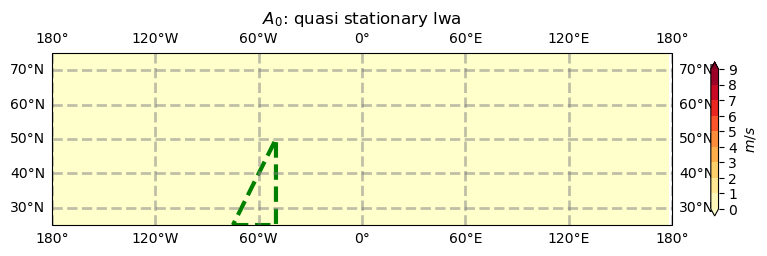

In [39]:
import cartopy.feature as cfeature

fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(10, 4))

# Set extent: lon from -180 to 180, lat from 25 to 75
ax.set_extent([-180, 180, 25, 75], crs=ccrs.PlateCarree())

# Plot the filled contours
contour = ax.contourf(
    lon,lat,slwa,
    levels=np.arange(0, 10, 1),
    cmap='YlOrRd',
    extend='both',
    transform=ccrs.PlateCarree()
)

ax.plot(lons, lats, linestyle='--',linewidth=3, color='green', transform=ccrs.PlateCarree())

ax.set_aspect(2)
gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                  linewidth=2, color='gray', alpha=0.5, linestyle='--')
gl.xlabels_top = False
gl.ylabels_right = False

# Add colorbar
cbar = plt.colorbar(contour, ax=ax, orientation='vertical', label='$m/s$',shrink=0.5)
plt.title('$A_0$: quasi stationary lwa')

plt.show()

### Compute the CARRYING CAPACITY

Here the carrying capacity is computed together with its associated error

In [40]:
# use shorter names
A = zgv + u_0
alpha = alpha
beta = beta
C = cosphi[0, :, :].copy()
L = slwa
B = L / C

# mean of the regression predictor, the same one used for beta_std
# (adjust if the regression predictor differs from A by the u_0 shift)
Abar = lwa_mean

# given stds 
sigma_A = zgv_std #basically u_0 has no error, or very very small
sigma_alpha = alpha_std #the error on beta depends on the error on alpha
sigma_L = slwa_std

# intermediate
u = A + beta - 2*alpha*B

# partial derivatives
dFC_dA     = (u * C) / (2.0 * alpha)
dFC_dbeta  = dFC_dA
dFC_dalpha = - (C * u * (4.0*B*alpha + u)) / (4.0 * alpha**2)
dFC_dL     = -u

# total derivative wrt alpha, using delta_beta = Abar * delta_alpha
dFC_dalpha_tot = dFC_dalpha + Abar * dFC_dbeta

# variance and std
FC_var = (
    (dFC_dalpha_tot**2) * sigma_alpha**2
  + (dFC_dA**2)         * sigma_A**2
  + (dFC_dL**2)         * sigma_L**2
)
FC_std = FC_var**0.5

# computed FC
FC = (u**2 * C) / (4.0 * alpha)

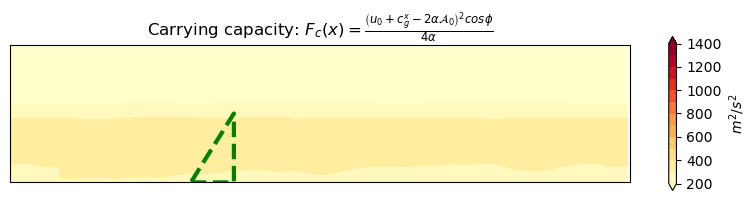

In [41]:
#TOTAL CARRYING CAPACITY

fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(10, 4))

# Set extent: lon from -180 to 180, lat from 25 to 75
ax.set_extent([-180, 180, 25, 75], crs=ccrs.PlateCarree())

# Plot the filled contours
contour = ax.contourf(
    lon,lat,FC,
    levels=np.arange(40, 300, 20)*5,
    cmap='YlOrRd',
    extend='both',
    transform=ccrs.PlateCarree()
)

ax.set_aspect(1.6)

ax.plot(lons, lats, linestyle='--',linewidth=3, color='green', transform=ccrs.PlateCarree())

# Add colorbar
cbar = plt.colorbar(contour, ax=ax, orientation='vertical', label='$m^2/s^2$',shrink=0.5)
plt.title('Carrying capacity: ' + r'$F_c(x) = \frac{\left( u_0 + c_g^x - 2\alpha \mathcal{A}_0 \right)^2 cos \phi}{4\alpha}$')

plt.show()

### Compute stationary wave activity flux
Here we compute the lwa flux associated with stationary local wave activity to remove it from the linear zonal flux

In [42]:
#COMPUTING STAT_LWA FLUX
cosphi2 = cosphi[0, :, :].copy()
slwa_Cw = slwa/cosphi2 #cosine weighted slwa
FA0 = (zgv+u_0+beta)*slwa_Cw*cosphi2 - alpha*(slwa_Cw**2)*cosphi2

### Comparison between FC and the transient zonal lwa flux


In [43]:
transient_flux = tot_zonal_flux - FA0
CLIM_transient_flux = transient_flux.mean('time')
PERC_transient_flux = transient_flux.quantile(0.85, dim='time')

/home/links/mf671/miniconda3/envs/prog_env/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1650: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


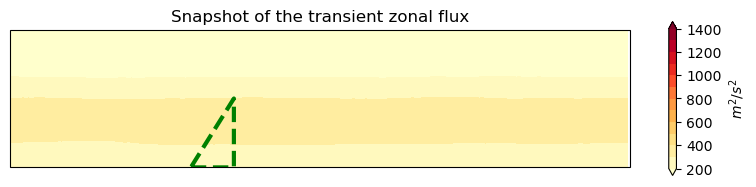

In [44]:
fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(10, 4))

# Set extent: lon from -180 to 180, lat from 25 to 75
ax.set_extent([-180, 180, 25, 75], crs=ccrs.PlateCarree())

# Plot the filled contours
contour = ax.contourf(
    lon,lat,PERC_transient_flux,
    levels=np.arange(40, 300, 20)*5,
    cmap='YlOrRd',
    extend='both',
    transform=ccrs.PlateCarree()
)

ax.set_aspect(1.6)
ax.plot(lons, lats, linestyle='--',linewidth=3, color='green', transform=ccrs.PlateCarree())

# Add colorbar
cbar = plt.colorbar(contour, ax=ax, orientation='vertical', label='$m^2/s^2$',shrink=0.5)
plt.title('Snapshot of the transient zonal flux')

plt.show()

In [45]:
# import blocking frequency
ds_blocks = xr.open_dataset("../tot/falwa_LWAA_tracked_flipped_2.5x2.5_daily_2-51.nc")
block_freq = ds_blocks['LWAA_freq']

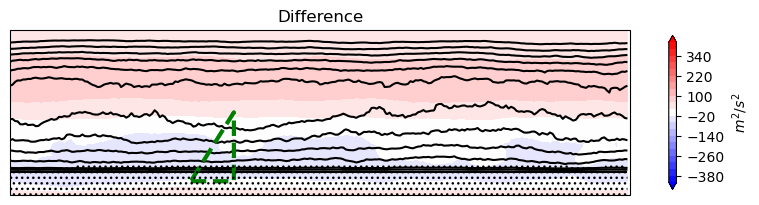

In [46]:
fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree()}, figsize=(10, 4))

# Set extent: lon from -180 to 180, lat from 25 to 75
ax.set_extent([-180, 180, 20, 80], crs=ccrs.PlateCarree())

# Plot the filled contours
contour = ax.contourf(
    lon,lat,PERC_transient_flux-FC,
#    lon,lat,CLIM_transient_flux-FC,
    levels=np.arange(-420, 430, 40),
    cmap='bwr',
    extend='both',
    transform=ccrs.PlateCarree()
)

ax.contour(lon,lat,block_freq,colors='k')

hatch_mask = np.where(r_mask, 1, np.nan)
ax.contourf(
    lon, lat, hatch_mask,
    levels=[0.5, 1.5],
    hatches=['...', None],
    colors='none',
    transform=ccrs.PlateCarree(),
    zorder=10
)

ax.set_aspect(1.6)
ax.plot(lons, lats, linestyle='--',linewidth=3, color='green', transform=ccrs.PlateCarree())

# Add colorbar
cbar = plt.colorbar(contour, ax=ax, orientation='vertical', label='$m^2/s^2$',shrink=0.5)
plt.title('Difference')

plt.show()

### Export dataset

In [47]:
#Create Carrying Capacity Dataset

alpha.name = 'alpha'
ds_out = alpha.to_dataset()
ds_out['zgv'] = zgv
ds_out['beta'] = beta
ds_out['qslwa'] = slwa
ds_out['lwa_mean'] = lwa_mean
ds_out['u_0'] = uref.mean('time').expand_dims({'lon': ds_out['lon']}).broadcast_like(ds_out['beta'])
ds_out['FC'] = FC
ds_out['FA0'] = FA0
ds_out['ue_A_rvalue'] = ue_A_rvalue
ds_out['CLIM_transient_flux'] = CLIM_transient_flux
ds_out['PERC_transient_flux'] = PERC_transient_flux

ds_out['alpha_std'] = alpha_std
ds_out['beta_std'] = beta_std
ds_out['qslwa_std'] = slwa_std
ds_out['zgv_std'] = zgv_std
ds_out['u_0_std'] = (uref.std('time')/np.sqrt(len(ds['time']))).expand_dims({'lon': ds_out['lon']}).broadcast_like(ds_out['beta'])
ds_out['FC_std'] = FC_std

ds_out.to_netcdf('../tot/FC_1.5x1.5_2-51_wbeta_uecorr.nc')